# Feature Engineering: Hands-on with Ames Housing

**Goal:** see how better *inputs* (features) reduce prediction error, using the **same model** every time.

| Step | Topic | Question it answers |
|---|---|---|
| 0 | Load data | What are we working with? |
| 1 | Scoreboard + baseline | What score do we need to beat? |
| 2 | Missing values | What do we do with gaps? |
| 3 | Categorical encoding | How do we use text columns? |
| 4 | Domain features | Can we hand the model what an expert would compute? |
| 5 | Transformations | What about skewed data? |
| 6 | Scaling | Why do feature scales matter? |
| 7 | Your turn | Invent your own feature |
| 8 | Recap | What helped, and what didn't? |

> **Rule for this notebook:** change *one thing at a time* and **measure** it.
>
> **Run the cells in order, once.** Each step modifies the table `X` built in the previous step. If something goes wrong, use *Runtime -> Restart and run all*.

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import Ridge

plt.rcParams["figure.figsize"] = (7, 4)

## 0. Load the data

**Ames Housing** (De Cock, 2011): about 1,460 home sales in Ames, Iowa, described by 79 columns. We predict `SalePrice` in US dollars.

It is a *real* and *messy* dataset, which is exactly why it is good for feature engineering: numbers, grades (Poor to Excellent), names (neighborhoods), blanks, and years.

> This downloads the dataset from OpenML, so it needs internet access (Colab has it).

The Ames Housing Dataset (compiled by Dean De Cock) contains 82 columns total in its raw format: 2930 observations described by 2 observation identifiers, 79 explanatory features, and 1 target variable (SalePrice). [1, 2]
The features are broken down into:

* 23 Nominal categorical variables
* 23 Ordinal categorical variables
* 14 Discrete numerical variables
* 20 Continuous numerical variables [3]

------------------------------
## Dataset Columns Breakdown## Identifiers & Target

* Order: Observation number (1 to 2930)
* PID: Parcel identification number (for use with city assessor maps)
* SalePrice (Target Variable): The property's sale price in US dollars [4]

## Lot & Location Features

* MSSubClass: The building class (type of dwelling, e.g., 1-story, 2-story, split-level)
* MSZoning: General zoning classification (e.g., Agricultural, Commercial, Floating Village, Residential Low/Medium/High Density)
* LotFrontage: Linear feet of street connected to property
* LotArea: Lot size in square feet
* Street: Type of road access (Pave, Grvl)
* Alley: Type of alley access (Grvl, Pave, NA)
* LotShape: General shape of property (Reg, IR1, IR2, IR3)
* LandContour: Flatness of the property (Lvl, Bnk, HLS, Low)
* Utilities: Type of utilities available (AllPub, NoSewr, NoSeWa, ELO)
* LotConfig: Lot configuration (Inside, Corner, CulDSac, FR2, FR3)
* LandSlope: Slope of property (Gtl, Mod, Sev)
* Neighborhood: Physical locations within Ames city limits (e.g., CollgCr, Veenker, Crawford)
* Condition1: Proximity to various conditions or railroads (e.g., Norm, Feedr, PosN)
* Condition2: Proximity to various conditions or railroads (if more than one) [4, 5, 6, 7, 8]

## Building & Type Characteristics

* BldgType: Type of dwelling (1Fam, 2FmCon, Duplx, TwnhsE, TwnhsI)
* HouseStyle: Style of dwelling (1Story, 2Story, 1.5Fin, etc.)
* OverallQual: Overall material and finish quality (1 to 10 scale)
* OverallCond: Overall condition rating (1 to 10 scale)
* YearBuilt: Original construction date
* YearRemodAdd: Remodel date (same as construction date if no remodeling)
* RoofStyle: Type of roof (Gable, Hip, Gambrel, etc.)
* RoofMatl: Roof material (Tar&Grv, WdShngl, Metal, etc.)
* Exterior1st: Exterior covering on house (VinylSd, HdBoard, MetalSd, etc.)
* Exterior2nd: Exterior covering on house (if more than one material)
* MasVnrType: Masonry veneer type (BrkCmn, BrkFace, None, Stone)
* MasVnrArea: Masonry veneer area in square feet
* ExterQual: Exterior material quality (Ex, TA, Gd, Fa)
* ExterCond: Present condition of the material on the exterior (Ex, TA, Gd, Fa, Po)
* Foundation: Type of foundation (PConc, CBlock, BrkTil, Slab, Stone, Wood) [7, 8]

## Basement Features

* BsmtQual: Height of the basement (Ex, Gd, TA, Fa, Po, NA)
* BsmtCond: General condition of the basement (Ex, Gd, TA, Fa, Po, NA)
* BsmtExposure: Walkout or garden level basement walls (Gd, Av, Mn, No, NA)
* BsmtFinType1: Rating of basement finished area (GLQ, ALQ, BLQ, Rec, LwQ, Unf, NA)
* BsmtFinSF1: Type 1 finished square feet
* BsmtFinType2: Rating of second finished area (if multiple types)
* BsmtFinSF2: Type 2 finished square feet
* BsmtUnfSF: Unfinished square feet of basement area
* TotalBsmtSF: Total square feet of basement area [8]

## Heating, Electrical, & Interior Rooms

* Heating: Type of heating (GasA, GasW, Grav, Wall, etc.)
* HeatingQC: Heating quality and condition (Ex, Gd, TA, Fa, Po)
* CentralAir: Central air conditioning (N, Y)
* Electrical: Electrical system (SBrkr, FuseA, FuseF, FuseP, Mix)
* 1stFlrSF: First Floor square feet
* 2ndFlrSF: Second floor square feet
* LowQualFinSF: Low quality finished square feet (all floors)
* GrLivArea: Above grade (ground) living area square feet
* BsmtFullBath: Basement full bathrooms
* BsmtHalfBath: Basement half bathrooms
* FullBath: Full bathrooms above grade
* HalfBath: Half baths above grade
* BedroomAbvGr: Bedrooms above grade (does not include basement bedrooms)
* KitchenAbvGr: Kitchens above grade
* KitchenQual: Kitchen quality (Ex, Gd, TA, Fa, Po)
* TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)
* Functional: Home functionality rating (Typ, Min1, Min2, Mod, Maj1, Maj2, Sev, Sal) [4, 7, 8]

## Fireplaces, Garages, & Outdoor Amenities

* Fireplaces: Number of fireplaces
* FireplaceQu: Fireplace quality (Ex, Gd, TA, Fa, Po, NA)
* GarageType: Garage location (Attchd, Detchd, BuiltIn, CarPort, etc.)
* GarageYrBlt: Year garage was built
* GarageFinish: Interior finish of the garage (Fin, RFn, Unf, NA)
* GarageCars: Size of garage in car capacity
* GarageArea: Size of garage in square feet
* GarageQual: Garage quality (Ex, Gd, TA, Fa, Po, NA)
* GarageCond: Garage condition (Ex, Gd, TA, Fa, Po, NA)
* PavedDrive: Paved driveway (Y, P, N)
* WoodDeckSF: Wood deck area in square feet
* OpenPorchSF: Open porch area in square feet
* EnclosedPorch: Enclosed porch area in square feet
* 3SsnPorch: Three season porch area in square feet
* ScreenPorch: Screen porch area in square feet
* PoolArea: Pool area in square feet
* PoolQC: Pool quality (Ex, Gd, TA, Fa, NA)
* Fence: Fence quality (GdPrv, MnPrv, GdWo, MnWw, NA)
* MiscFeature: Miscellaneous feature not covered in other categories (Elev, Gar2, Othr, Shed, TenC, NA)
* MiscVal: Dollar value of miscellaneous feature [7, 8, 9]

## Sale Metadata

* MoSold: Month sold (1 to 12)
* YrSold: Year sold (2006 to 2010)
* SaleType: Type of sale (WD, New, COD, Con, etc.)
* SaleCondition: Condition of sale (Normal, Abnorml, AdjLand, Alloca, Family, Partial) [7, 8, 10]

In [82]:
housing = fetch_openml(data_id=42165, as_frame=True, parser="auto")
df = housing.frame.drop(columns=["Id"], errors="ignore")   # row id carries no information

y = df["SalePrice"]          # the target: what we want to predict
print("Rows, columns:", df.shape)
df[["SalePrice", "GrLivArea", "LotArea", "YearBuilt", "YrSold", "Neighborhood", "ExterQual", "PoolQC"]].head()

Rows, columns: (1460, 80)


,SalePrice,GrLivArea,LotArea,YearBuilt,YrSold,Neighborhood,ExterQual,PoolQC
0,208500,1710,8450,2003,2008,CollgCr,Gd,NaN
1,181500,1262,9600,1976,2007,Veenker,TA,NaN
2,223500,1786,11250,2001,2008,CollgCr,Gd,NaN
3,140000,1717,9550,1915,2006,Crawfor,TA,NaN
4,250000,2198,14260,2000,2008,NoRidge,Gd,NaN


### Look at the raw data

Two things to notice: how many columns have gaps, and how skewed the numbers are.

Columns with any missing values: 19 of 80
PoolQC          99.5 %
MiscFeature     96.3 %
Alley           93.8 %
Fence           80.8 %
FireplaceQu     47.3 %
LotFrontage     17.7 %
GarageQual       5.5 %
GarageYrBlt      5.5 %
GarageType       5.5 %
GarageFinish     5.5 %
GarageCond       5.5 %
BsmtExposure     2.6 %
dtype: object


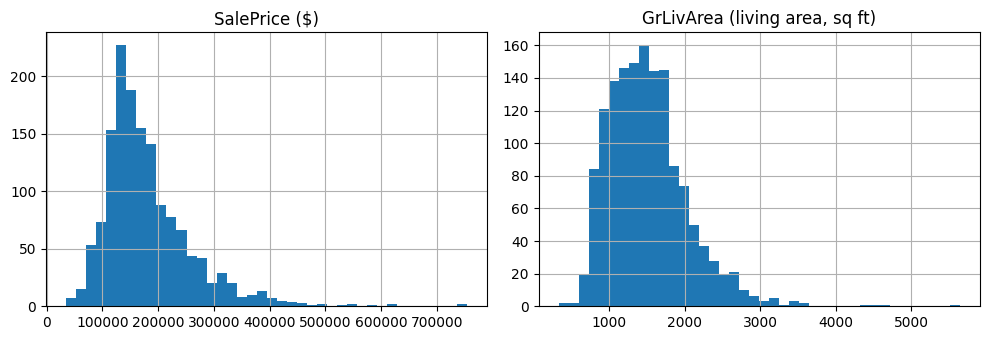

In [83]:
missing = df.isna().mean().sort_values(ascending=False)
print("Columns with any missing values:", (missing > 0).sum(), "of", df.shape[1])
print((missing[missing > 0].head(12) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["SalePrice"].hist(bins=40, ax=ax[0]); ax[0].set_title("SalePrice ($)")
df["GrLivArea"].hist(bins=40, ax=ax[1]); ax[1].set_title("GrLivArea (living area, sq ft)")
plt.tight_layout(); plt.show()

In [84]:
df["SalePrice"].skew()

np.float64(1.8828757597682129)

In [85]:
df.shape

(1460, 80)

## 1. The scoreboard and a baseline

We need a fair way to compare feature sets. The function below is our **scoreboard**:

> You give it a table of features. It tells you how far off its predicted prices are, **on average, in dollars** (this is the *RMSE*). **Lower is better.**

Inside, it uses a prediction model and a testing procedure that we'll cover later in the course. For now treat it as a **black box**. It only *scores*; it never changes your data. So the table you hand it must already be **all numbers with no gaps**.

In [86]:
results = {}     # the scoreboard remembers every score here

def scoreboard(X, name):
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(Ridge(alpha=10), X, y, cv=cv, scoring="neg_root_mean_squared_error", error_score="raise")
    results[name] = -scores.mean()
    print(f"{name:<34} average error = ${-scores.mean():>9,.0f}")

### First attempt: use the numeric columns as they are

In [87]:
num = df.select_dtypes("number").drop(columns="SalePrice")   # numeric columns only
print("Numeric columns:", num.shape[1])

try:
    scoreboard(num, "0. raw numeric columns")
except ValueError as e:
    print("Error:", str(e)[:120], "...")

Numeric columns: 36
Error: Input X contains NaN.
Ridge does not accept missing values encoded as NaN natively. For supervised learning, you might w ...


In [88]:
num.shape

(1460, 36)

The model refuses: **it cannot handle gaps (NaN)**. That brings us to our first feature-engineering task.

## 2. Missing values

**First question: *why* is it missing?** Check the data dictionary, because the answer changes the fix.

| Kind of missing | Example | Fix |
|---|---|---|
| Truly unknown number | `LotFrontage`, `GarageYrBlt` | Fill with the **median** *and* add a flag column "was missing" |
| Not applicable (absence is the answer) | `PoolQC`, `Alley`, `Fence` | Fill with the category `"None"` |

Let's start with the numeric columns. Filling gaps with the **median** (the middle value) is the simplest option, and it isn't thrown off by extreme values. This gives us our **baseline**.

In [89]:
X = num.fillna(num.median())      # replace each gap with its column's median

scoreboard(X, "1. Baseline (numbers only)")

1. Baseline (numbers only)         average error = $   37,742


In [90]:
X.shape

(1460, 36)

That number is our **reference line**. Everything from here on is measured against it.

Now add a **flag column** for every numeric column that had gaps, so the model can tell "this value was missing" apart from a real value.

In [91]:
cols_with_gaps = num.columns[num.isna().any()]
print("Columns with gaps:", list(cols_with_gaps))

for c in cols_with_gaps:
    X[c + "_missing"] = num[c].isna().astype(int)     # 1 = was missing, 0 = was recorded

scoreboard(X, "2. + missing-value flags")

Columns with gaps: ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']
2. + missing-value flags           average error = $   37,458


In [92]:
cols_with_gaps

Index(['LotFrontage', 'MasVnrArea', 'GarageYrBlt'], dtype='object')

In [93]:
X.shape

(1460, 39)

In [94]:
for i, v in enumerate(X.columns):
  print(f"{i}. {v}")

0. MSSubClass
1. LotFrontage
2. LotArea
3. OverallQual
4. OverallCond
5. YearBuilt
6. YearRemodAdd
7. MasVnrArea
8. BsmtFinSF1
9. BsmtFinSF2
10. BsmtUnfSF
11. TotalBsmtSF
12. 1stFlrSF
13. 2ndFlrSF
14. LowQualFinSF
15. GrLivArea
16. BsmtFullBath
17. BsmtHalfBath
18. FullBath
19. HalfBath
20. BedroomAbvGr
21. KitchenAbvGr
22. TotRmsAbvGrd
23. Fireplaces
24. GarageYrBlt
25. GarageCars
26. GarageArea
27. WoodDeckSF
28. OpenPorchSF
29. EnclosedPorch
30. 3SsnPorch
31. ScreenPorch
32. PoolArea
33. MiscVal
34. MoSold
35. YrSold
36. LotFrontage_missing
37. MasVnrArea_missing
38. GarageYrBlt_missing


> **Think:** the score barely moves. Why bother? Because the flags cost nothing, and sometimes "missing" is itself a signal. The big payoff comes next, when we can use the *text* columns.

## 3. Categorical encoding

So far we ignored every text column, including `Neighborhood`. Models need numbers, and two kinds of text columns need two different treatments:

| Type | Example | Treatment |
|---|---|---|
| **Ordinal** (natural order) | `ExterQual`: Poor < Fair < Typical < Good < Excellent | Map to numbers 1, 2, 3, 4, 5 (keeps the order) |
| **Nominal** (no order) | `Neighborhood`, `MSZoning` | **One-hot**: one 0/1 column per value |

One-hot encoding in a nutshell:

In [95]:
pd.get_dummies(df["MSZoning"].head(6), dtype=int)     # each row has a 1 in exactly one column

,RL
0,1
1,1
2,1
3,1
4,1
5,1


Now the real thing. Three small things to handle along the way:

1. In text columns, "missing" means *the house doesn't have one* (no pool, no alley...), so we fill with `"None"`.
2. `MSSubClass` is stored as a number (20, 60, 120...) but these are **codes for building types**. Code 120 is not six times code 20, so we treat it as text.
3. Ordinal columns get a numeric grade; everything else gets one-hot.

In [96]:
text = df.select_dtypes(exclude="number").astype(object).fillna("None")   # NA means "does not have one"

text["MSSubClass"] = df["MSSubClass"].astype(str)       # a code, not a quantity
X = X.drop(columns="MSSubClass")                        # remove its numeric version

# ordinal columns: map the grades to numbers
grade = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ordinal_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for c in ordinal_cols:
    text[c] = text[c].map(grade)

# every remaining text column becomes one-hot columns
text = pd.get_dummies(text, dtype=int)

X = pd.concat([X, text], axis=1)
print("Features now:", X.shape[1])

scoreboard(X, "3. + categorical encoding")

Features now: 280
3. + categorical encoding          average error = $   34,391


This is usually the **biggest jump of the whole session**. The baseline ignored most of the dataset, including the neighborhood, the classic real-estate predictor.

## 4. Domain-derived features

Ask: **"What would a human expert compute in their head before guessing the price?"**

| New feature | Formula | Why a buyer cares |
|---|---|---|
| `HouseAge` | `YrSold - YearBuilt` | Age at sale matters more than the raw year |
| `RemodAge` | `YrSold - YearRemodAdd` | Recent renovation signals condition |
| `TotalSF` | basement + 1st floor + 2nd floor | Total space in a single number |
| `TotalBath` | full + 0.5 x half (above and below ground) | One bathroom count |
| `HasPool` | `PoolArea > 0` | Rare but valuable; a flag is cleaner than a mostly-zero column |
| `WasRemodeled` | `YearRemodAdd != YearBuilt` | Yes / no signal |

The model does not automatically subtract or add columns. We do it for it.

In [97]:
X["HouseAge"]     = X["YrSold"] - X["YearBuilt"]
X["RemodAge"]     = X["YrSold"] - X["YearRemodAdd"]
X["TotalSF"]      = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
X["TotalBath"]    = X["FullBath"] + 0.5 * X["HalfBath"] + X["BsmtFullBath"] + 0.5 * X["BsmtHalfBath"]
X["HasPool"]      = (X["PoolArea"] > 0).astype(int)
X["WasRemodeled"] = (X["YearRemodAdd"] != X["YearBuilt"]).astype(int)

scoreboard(X, "4. + domain features")

4. + domain features               average error = $   34,416


## 5. Transformations: taming skew

Areas, prices and incomes are *right-skewed*: most values are modest, a few are enormous.

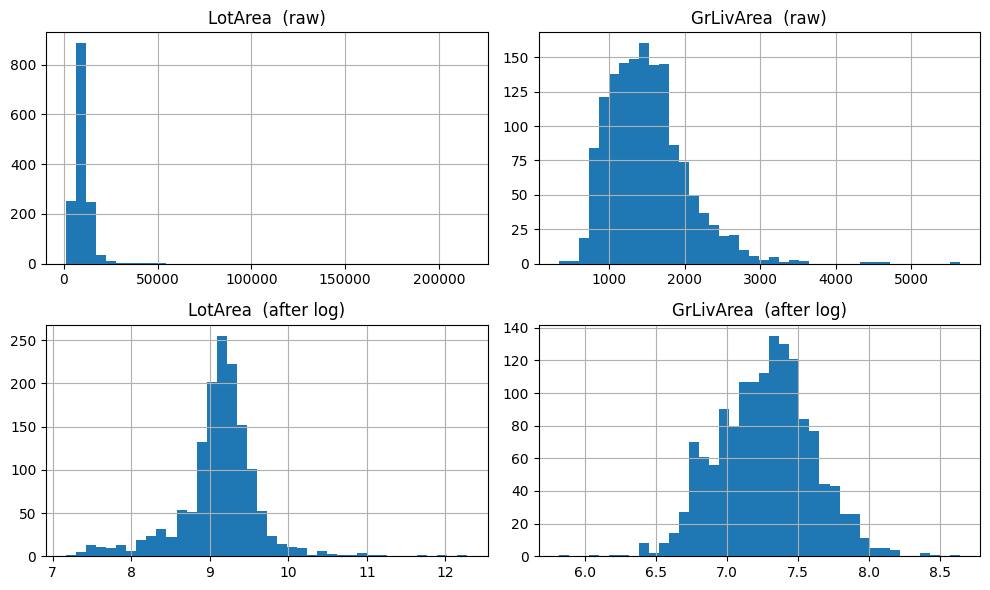

In [98]:
skewed = ["LotArea", "GrLivArea", "1stFlrSF", "LotFrontage", "TotalSF"]

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for j, c in enumerate(["LotArea", "GrLivArea"]):
    X[c].hist(bins=40, ax=ax[0, j]);           ax[0, j].set_title(f"{c}  (raw)")
    np.log1p(X[c]).hist(bins=40, ax=ax[1, j]); ax[1, j].set_title(f"{c}  (after log)")
plt.tight_layout(); plt.show()

`log1p(x) = log(1 + x)` compresses the long tail (the "+1" keeps zeros safe). It also matches intuition: going from 1,000 to 2,000 sq ft matters a lot; going from 10,000 to 11,000 barely does.

In [99]:
for c in skewed:
    X[c] = np.log1p(X[c])

scoreboard(X, "5. + log transform")

5. + log transform                 average error = $   34,118


## 6. Scaling

Features live on very different scales:

In [100]:
X[["LotArea", "GrLivArea", "OverallQual", "YearBuilt"]].agg(["mean", "std"]).round(1)

,LotArea,GrLivArea,OverallQual,YearBuilt
mean,9.1,7.3,6.1,1971.3
std,0.5,0.3,1.4,30.2


`YearBuilt` is around 1,970 while `OverallQual` runs from 1 to 10. Many models, including the one inside our scoreboard, **penalize large weights**. A feature with big numbers needs only a tiny weight, so it is barely penalized, while a feature with small numbers needs a large weight and is penalized heavily. The units alone decide who gets treated fairly.

**Fix: standardize.** Subtract the column's mean and divide by its standard deviation, so every column has mean 0 and spread 1:

$$z = \frac{x - \text{mean}}{\text{std}}$$

We do this **last**, after all the columns are in their final form.

In [101]:
X = (X - X.mean()) / X.std()

scoreboard(X, "6. + scaling")

6. + scaling                       average error = $   35,433


> **Think:** would a decision tree need this step? (Trees only ask "is this value above or below a cut-off?", so rescaling does not change their answers.)

## 7. Your turn (about 8 minutes)

Invent **one** new feature and test whether it improves the score. Write it in the marked line using columns from `df` (the original, unscaled data). The next lines tidy it up and add it to a copy of the final table.

**Idea bank**

| Idea | Formula |
|---|---|
| Garage age | `df["YrSold"] - df["GarageYrBlt"]` |
| Total porch area | `df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"]` |
| Quality x size | `df["OverallQual"] * df["GrLivArea"]` |
| Average room size | `df["GrLivArea"] / df["TotRmsAbvGrd"]` |
| Lot usage | `df["1stFlrSF"] / df["LotArea"]` |

**Rules**
- Use only *input* columns. Never build a feature from `SalePrice` (that would be cheating).
- A feature that doesn't help is a valid, useful result. Report it!

In [102]:
X_mine = X.copy()

# ---- YOUR IDEA HERE: one line that produces a new column -------------
new = df["YrSold"] - df["GarageYrBlt"]
# -----------------------------------------------------------------------

new = new.replace([np.inf, -np.inf], np.nan)               # division by zero -> gap
new = new.fillna(new.median())                             # fill gaps (as in step 2)
X_mine["MyFeature"] = (new - new.mean()) / new.std()       # scale it (as in step 6)

scoreboard(X_mine, "7. + my feature")
print("Change vs. step 6: $", round(results["7. + my feature"] - results["6. + scaling"]), "(negative = better)")

7. + my feature                    average error = $   35,434
Change vs. step 6: $ 1 (negative = better)


## 8. Recap

### The scoreboard

                            average error ($) change vs. baseline
1. Baseline (numbers only)            37742.0               0.0 %
2. + missing-value flags              37458.0              -0.8 %
3. + categorical encoding             34391.0              -8.9 %
4. + domain features                  34416.0              -8.8 %
5. + log transform                    34118.0              -9.6 %
6. + scaling                          35433.0              -6.1 %
7. + my feature                       35434.0              -6.1 %


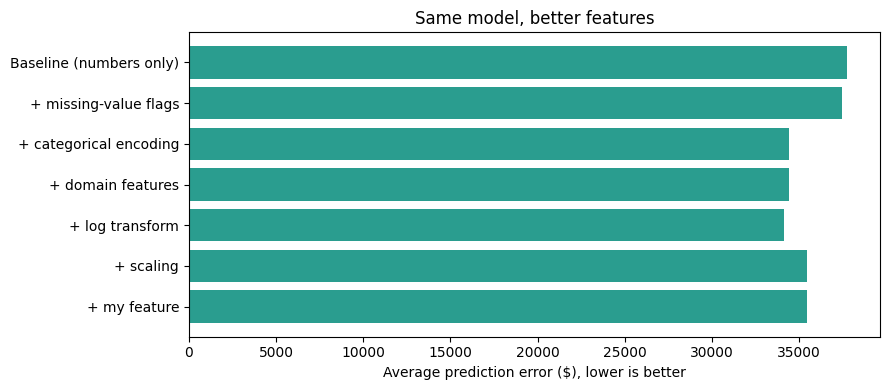

In [103]:
board = pd.DataFrame({"average error ($)": pd.Series(results).round(0)})
first = board["average error ($)"].iloc[0]
board["change vs. baseline"] = ((board["average error ($)"] / first - 1) * 100).round(1).astype(str) + " %"
print(board.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
labels = [k.split(". ", 1)[1] if ". " in k else k for k in results]
ax.barh(labels[::-1], list(results.values())[::-1], color="#2a9d8f")
ax.set_xlabel("Average prediction error ($), lower is better")
ax.set_title("Same model, better features")
plt.tight_layout(); plt.show()

### Take-home messages

1. **Understand the data first.** Missing can mean "none"; a number can really be a category.
2. **Measure every change.** One change at a time, against a baseline.
3. **Not every feature helps.** Keep the ones that earn their place.

### Where to go next
- Training and testing properly (the scoreboard's black box, opened)
- Feature selection
- Tree-based models: less scaling work, but domain features still help
- Try the same workflow on a new dataset, such as NYC taxi trips or bike-share demand